## Importing Libraries


In [69]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Loading the raw dataset

In [70]:
df=pd.read_csv('P:\\Customer Churn Telecom-OTT\\data\\raw_customer_churn.csv')

In [71]:
display(df.head())

,customer_id,tenure_months,monthly_fee,total_usage_last_30d,support_tickets_last_90d,has_outstanding_invoice,discount_received_last_6m,num_competing_offers_in_region,is_premium_plan,engagement_score,region,device_type,customer_segment,csat_score,cltv_estimated,preferred_contact,churn_next_30d
0,CUST-100000,52,66.61,299.1,2,0,0.0,0,0,78.0,North America,Desktop,SMB,3.0,6165.42,Phone,0
1,CUST-100001,15,48.26,173.7,2,1,NaN,4,1,49.2,Middle East & Africa,Tablet,Consumer,5.0,1080.06,SMS,1
2,CUST-100002,61,96.9,197.7,5,0,0.0,2,0,51.9,NaN,Desktop,SMB,2.0,8978.66,In-App,1
3,CUST-100003,21,148,136.0,2,1,0.0,4,0,39.7,Asia-Pacific,Smart TV,Enterprise,2.0,4341.88,Phone,0
4,CUST-100004,24,84.88,234.0,3,1,0.0,1,0,66.6,Latin America,Mobile,SMB,4.0,3393.84,SMS,0


## Overview of the dataset(Data Inspection)

In [72]:
print("SHAPE:",df.shape)
print("COLUMNS:",df.columns)

SHAPE: (34000, 17)
COLUMNS: Index(['customer_id', 'tenure_months', 'monthly_fee', 'total_usage_last_30d',
       'support_tickets_last_90d', 'has_outstanding_invoice',
       'discount_received_last_6m', 'num_competing_offers_in_region',
       'is_premium_plan', 'engagement_score', 'region', 'device_type',
       'customer_segment', 'csat_score', 'cltv_estimated', 'preferred_contact',
       'churn_next_30d'],
      dtype='object')


In [73]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34000 entries, 0 to 33999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   customer_id                     34000 non-null  object 
 1   tenure_months                   34000 non-null  object 
 2   monthly_fee                     34000 non-null  object 
 3   total_usage_last_30d            32980 non-null  float64
 4   support_tickets_last_90d        34000 non-null  int64  
 5   has_outstanding_invoice         34000 non-null  int64  
 6   discount_received_last_6m       32980 non-null  float64
 7   num_competing_offers_in_region  34000 non-null  int64  
 8   is_premium_plan                 34000 non-null  int64  
 9   engagement_score                32980 non-null  float64
 10  region                          32980 non-null  object 
 11  device_type                     34000 non-null  object 
 12  customer_segment                

In [74]:
print("Missing Values:")
df.isnull().sum().sort_values(ascending=False) 

Missing Values:


csat_score                        1659
region                            1020
total_usage_last_30d              1020
engagement_score                  1020
discount_received_last_6m         1020
preferred_contact                 1020
customer_id                          0
monthly_fee                          0
tenure_months                        0
is_premium_plan                      0
num_competing_offers_in_region       0
has_outstanding_invoice              0
support_tickets_last_90d             0
customer_segment                     0
device_type                          0
cltv_estimated                       0
churn_next_30d                       0
dtype: int64

In [75]:
df.describe(include='number')


,total_usage_last_30d,support_tickets_last_90d,has_outstanding_invoice,discount_received_last_6m,num_competing_offers_in_region,is_premium_plan,engagement_score,csat_score,cltv_estimated,churn_next_30d
count,32980.000000,34000.000000,34000.000000,32980.000000,34000.000000,34000.000000,32980.000000,32341.000000,34000.000000,34000.000000
mean,224.862092,1.793912,0.279529,0.246180,1.406882,0.351206,64.205579,3.263597,4980.127099,0.115147
std,61.792532,1.581375,0.448775,0.430791,1.279417,0.477354,16.657709,1.205864,4077.184903,0.319204
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,21.430000,0.000000
25%,182.700000,1.000000,0.000000,0.000000,0.000000,0.000000,52.800000,2.000000,1710.687500,0.000000
50%,225.400000,1.000000,0.000000,0.000000,1.000000,0.000000,64.300000,3.000000,3855.305000,0.000000
75%,267.300000,3.000000,1.000000,0.000000,2.000000,1.000000,75.700000,4.000000,7376.915000,0.000000
max,412.300000,12.000000,1.000000,1.000000,4.000000,1.000000,100.000000,5.000000,21213.380000,1.000000


In [76]:
df.describe(include='object')

,customer_id,tenure_months,monthly_fee,region,device_type,customer_segment,preferred_contact
count,34000,34000,34000,32980,34000,34000,32980
unique,34000,138,12587,5,4,3,4
top,CUST-133983,17,102.27,North America,Desktop,Consumer,In-App
freq,1,545,11,11532,13482,18726,8431


In [77]:
# Checking the target variable distribution
df['churn_next_30d'].value_counts(normalize='True')

churn_next_30d
0    0.884853
1    0.115147
Name: proportion, dtype: float64

In [78]:
for col in df.columns:
    if df[col].dtype == 'object':
        print(col,"--",df[col].unique())

customer_id -- ['CUST-100000' 'CUST-100001' 'CUST-100002' ... 'CUST-133997' 'CUST-133998'
 'CUST-133999']
tenure_months -- ['52' '15' '61' '21' '24' '3' '22' '53' '2' '30' '38' '64' '60' '33' '58'
 '49' '59' '42' '62' '47' '51' '55' '7' '39' '18' '4' '14' '9' '71' '44'
 '8' '35' '36' '50' '6' '54' '63' '34' '48' '40' '26' '41' '29' '45' '65'
 '1' '11' '5' '28' '12' '23' '37' '44 months' '27' '43' '13' '32' '66'
 '57' '70' '56' '19' '68' '17' '69' '16' '20' '67' '19 months' '31'
 '20 months' '24 months' '25' '46' '10' '56 months' '70 months'
 '40 months' '66 months' '39 months' '52 months' '59 months' '67 months'
 '51 months' '50 months' '15 months' '30 months' '21 months' '27 months'
 '69 months' '37 months' '05 months' '68 months' '38 months' '62 months'
 '10 months' '07 months' '43 months' '60 months' '13 months' '02 months'
 '01 months' '57 months' '26 months' '17 months' '71 months' '22 months'
 '32 months' '49 months' '11 months' '47 months' '16 months' '09 months'
 '06 months' '3

In [79]:
missing_cols = [
    "csat_score",
    "region",
    "total_usage_last_30d",
    "engagement_score",
    "discount_received_last_6m",
    "preferred_contact"
]

df[missing_cols].isnull().sum(axis=1).value_counts()

0    27755
1     5753
2      471
3       20
4        1
Name: count, dtype: int64

In [80]:
for col in missing_cols:
    print(df.groupby(df[col].isnull())['churn_next_30d'].mean())

csat_score
False    0.115457
True     0.109102
Name: churn_next_30d, dtype: float64
region
False    0.115252
True     0.111765
Name: churn_next_30d, dtype: float64
total_usage_last_30d
False    0.115646
True     0.099020
Name: churn_next_30d, dtype: float64
engagement_score
False    0.115464
True     0.104902
Name: churn_next_30d, dtype: float64
discount_received_last_6m
False    0.115403
True     0.106863
Name: churn_next_30d, dtype: float64
preferred_contact
False    0.114918
True     0.122549
Name: churn_next_30d, dtype: float64


## Data Cleaning

In [81]:
#Backingup dataset
df_clean=df.copy()

In [82]:
df_clean.dtypes

customer_id                        object
tenure_months                      object
monthly_fee                        object
total_usage_last_30d              float64
support_tickets_last_90d            int64
has_outstanding_invoice             int64
discount_received_last_6m         float64
num_competing_offers_in_region      int64
is_premium_plan                     int64
engagement_score                  float64
region                             object
device_type                        object
customer_segment                   object
csat_score                        float64
cltv_estimated                    float64
preferred_contact                  object
churn_next_30d                      int64
dtype: object

tenure_months and monthly_fee have dirty data and should be int/float instead of object dtype.

In [83]:

print("Duplicate rows:", df_clean.duplicated().sum())
print("Duplicate customer IDs:", df_clean["customer_id"].duplicated().sum())

Duplicate rows: 0
Duplicate customer IDs: 0


In [84]:
df['tenure_months'].unique()

array(['52', '15', '61', '21', '24', '3', '22', '53', '2', '30', '38',
       '64', '60', '33', '58', '49', '59', '42', '62', '47', '51', '55',
       '7', '39', '18', '4', '14', '9', '71', '44', '8', '35', '36', '50',
       '6', '54', '63', '34', '48', '40', '26', '41', '29', '45', '65',
       '1', '11', '5', '28', '12', '23', '37', '44 months', '27', '43',
       '13', '32', '66', '57', '70', '56', '19', '68', '17', '69', '16',
       '20', '67', '19 months', '31', '20 months', '24 months', '25',
       '46', '10', '56 months', '70 months', '40 months', '66 months',
       '39 months', '52 months', '59 months', '67 months', '51 months',
       '50 months', '15 months', '30 months', '21 months', '27 months',
       '69 months', '37 months', '05 months', '68 months', '38 months',
       '62 months', '10 months', '07 months', '43 months', '60 months',
       '13 months', '02 months', '01 months', '57 months', '26 months',
       '17 months', '71 months', '22 months', '32 months', '49 

In [85]:
#Cleaning tenure_months 
df_clean['tenure_months']=(
    df['tenure_months']
    .str.extract(r"(\d+\.?\d*)")[0]
    .astype(float)
)

In [86]:
#Cleaning monthly_fee
df_clean['monthly_fee']=(
    df['monthly_fee']
    .str.replace("$","",regex=False)
    .str.replace(",","",regex=False)
    .astype(float)
)

In [87]:
df_clean[['tenure_months', 'monthly_fee']].dtypes

tenure_months    float64
monthly_fee      float64
dtype: object

In [88]:
df_clean[['tenure_months', 'monthly_fee']].head()

,tenure_months,monthly_fee
0,52.0,66.61
1,15.0,48.26
2,61.0,96.90
3,21.0,148.00
4,24.0,84.88


In [89]:
df_clean[['tenure_months', 'monthly_fee']].isnull().sum()

tenure_months    0
monthly_fee      0
dtype: int64

In [90]:
df_clean[['tenure_months', 'monthly_fee']].describe()

,tenure_months,monthly_fee
count,34000.000000,34000.000000
mean,35.959382,82.443647
std,20.465490,38.979795
min,1.000000,15.000000
25%,18.000000,48.757500
50%,36.000000,82.430000
75%,54.000000,116.220000
max,71.000000,150.000000


### Checking for inappropriate data 

In [91]:
numeric_cols = df_clean.select_dtypes(include=np.number).columns

df_clean[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
tenure_months,34000.0,35.959382,20.465490,1.00,18.0000,36.000,54.000,71.00
monthly_fee,34000.0,82.443647,38.979795,15.00,48.7575,82.430,116.220,150.00
total_usage_last_30d,32980.0,224.862092,61.792532,0.00,182.7000,225.400,267.300,412.30
support_tickets_last_90d,34000.0,1.793912,1.581375,0.00,1.0000,1.000,3.000,12.00
has_outstanding_invoice,34000.0,0.279529,0.448775,0.00,0.0000,0.000,1.000,1.00
discount_received_last_6m,32980.0,0.246180,0.430791,0.00,0.0000,0.000,0.000,1.00
num_competing_offers_in_region,34000.0,1.406882,1.279417,0.00,0.0000,1.000,2.000,4.00
is_premium_plan,34000.0,0.351206,0.477354,0.00,0.0000,0.000,1.000,1.00
engagement_score,32980.0,64.205579,16.657709,0.00,52.8000,64.300,75.700,100.00
csat_score,32341.0,3.263597,1.205864,1.00,2.0000,3.000,4.000,5.00


In [92]:
#csat_score should be between 1 and 5
df_clean['csat_score'].value_counts().sort_index()

csat_score
1.0     3330
2.0     5231
3.0     8517
4.0    10110
5.0     5153
Name: count, dtype: int64

In [93]:
#engagement_score should be between 0 and 100
df_clean.loc[(df_clean['engagement_score']<0) | (df_clean['engagement_score']>100), 'engagement_score']

Series([], Name: engagement_score, dtype: float64)

In [94]:
#binary colums check
binary_cols=['has_outstanding_invoice','discount_received_last_6m','is_premium_plan']

for col in binary_cols:
    print(df_clean[col].value_counts().sort_index())

has_outstanding_invoice
0    24496
1     9504
Name: count, dtype: int64
discount_received_last_6m
0.0    24861
1.0     8119
Name: count, dtype: int64
is_premium_plan
0    22059
1    11941
Name: count, dtype: int64


In [95]:
#changing the data type of binary columns to category
for col in binary_cols:
    df_clean[col]=df_clean[col].astype('category')
df_clean[binary_cols].dtypes

has_outstanding_invoice      category
discount_received_last_6m    category
is_premium_plan              category
dtype: object

In [96]:
to_category_cols = ['region','preferred_contact','device_type','customer_segment']
for col in to_category_cols:
    df_clean[col]=df_clean[col].astype('category')

In [97]:
df_clean.dtypes

customer_id                         object
tenure_months                      float64
monthly_fee                        float64
total_usage_last_30d               float64
support_tickets_last_90d             int64
has_outstanding_invoice           category
discount_received_last_6m         category
num_competing_offers_in_region       int64
is_premium_plan                   category
engagement_score                   float64
region                            category
device_type                       category
customer_segment                  category
csat_score                         float64
cltv_estimated                     float64
preferred_contact                 category
churn_next_30d                       int64
dtype: object

### Handling Missing Values

In [98]:
df.isna().sum().sort_values(ascending=False)

csat_score                        1659
region                            1020
total_usage_last_30d              1020
engagement_score                  1020
discount_received_last_6m         1020
preferred_contact                 1020
customer_id                          0
monthly_fee                          0
tenure_months                        0
is_premium_plan                      0
num_competing_offers_in_region       0
has_outstanding_invoice              0
support_tickets_last_90d             0
customer_segment                     0
device_type                          0
cltv_estimated                       0
churn_next_30d                       0
dtype: int64

* Numeric=csat_score,total_usage_last_30d,engagement_score
* Categorical=region,discount_received_last_6m,preferred_contact

In [99]:
df_clean[
    [
    "csat_score",
    "total_usage_last_30d",
    "engagement_score"
    ]
].describe().T

,count,mean,std,min,25%,50%,75%,max
csat_score,32341.0,3.263597,1.205864,1.0,2.0,3.0,4.0,5.0
total_usage_last_30d,32980.0,224.862092,61.792532,0.0,182.7,225.4,267.3,412.3
engagement_score,32980.0,64.205579,16.657709,0.0,52.8,64.3,75.7,100.0


In [100]:
for col in ["region", "discount_received_last_6m", "preferred_contact","discount_received_last_6m"]:
    print(df_clean[col].value_counts(dropna=False))

region
North America           11532
Europe                   8299
Asia-Pacific             6491
Latin America            4074
Middle East & Africa     2584
NaN                      1020
Name: count, dtype: int64
discount_received_last_6m
 0.0    24861
 1.0     8119
NaN      1020
Name: count, dtype: int64
preferred_contact
In-App    8431
Phone     8219
SMS       8207
Email     8123
NaN       1020
Name: count, dtype: int64
discount_received_last_6m
 0.0    24861
 1.0     8119
NaN      1020
Name: count, dtype: int64


In [101]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34000 entries, 0 to 33999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype   
---  ------                          --------------  -----   
 0   customer_id                     34000 non-null  object  
 1   tenure_months                   34000 non-null  float64 
 2   monthly_fee                     34000 non-null  float64 
 3   total_usage_last_30d            32980 non-null  float64 
 4   support_tickets_last_90d        34000 non-null  int64   
 5   has_outstanding_invoice         34000 non-null  category
 6   discount_received_last_6m       32980 non-null  category
 7   num_competing_offers_in_region  34000 non-null  int64   
 8   is_premium_plan                 34000 non-null  category
 9   engagement_score                32980 non-null  float64 
 10  region                          32980 non-null  category
 11  device_type                     34000 non-null  category
 12  customer_segment  

In [102]:
df_clean.to_csv('P:\\Customer Churn Telecom-OTT\\data\\cleaned_customer_churn.csv',index=False)

## 4. Exploratory Data Analysis

In [103]:
plot_df=df_clean.copy()

In [104]:
plot_df['churn_next_30d'].value_counts()

churn_next_30d
0    30085
1     3915
Name: count, dtype: int64

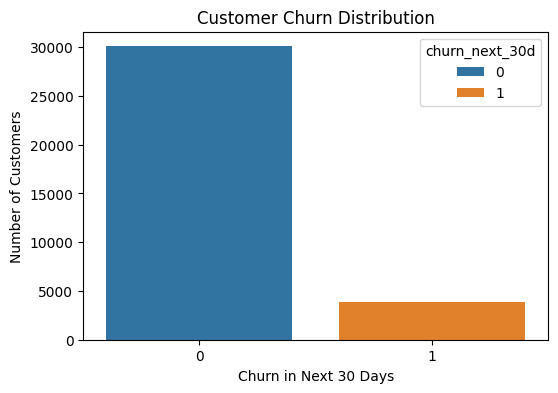

In [105]:
plt.figure(figsize=(6,4))
sns.countplot(data=plot_df,x='churn_next_30d',hue=plot_df['churn_next_30d'])
plt.title("Customer Churn Distribution")
plt.xlabel("Churn in Next 30 Days")
plt.ylabel("Number of Customers")
plt.show()

In [106]:
plot_df['churn_next_30d'].value_counts(normalize=True)*100

churn_next_30d
0    88.485294
1    11.514706
Name: proportion, dtype: float64

The dataset contains a class imbalance, with approximately 11.5% of customers expected to churn within the next 30 days.

In [107]:
plot_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34000 entries, 0 to 33999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype   
---  ------                          --------------  -----   
 0   customer_id                     34000 non-null  object  
 1   tenure_months                   34000 non-null  float64 
 2   monthly_fee                     34000 non-null  float64 
 3   total_usage_last_30d            32980 non-null  float64 
 4   support_tickets_last_90d        34000 non-null  int64   
 5   has_outstanding_invoice         34000 non-null  category
 6   discount_received_last_6m       32980 non-null  category
 7   num_competing_offers_in_region  34000 non-null  int64   
 8   is_premium_plan                 34000 non-null  category
 9   engagement_score                32980 non-null  float64 
 10  region                          32980 non-null  category
 11  device_type                     34000 non-null  category
 12  customer_segment  

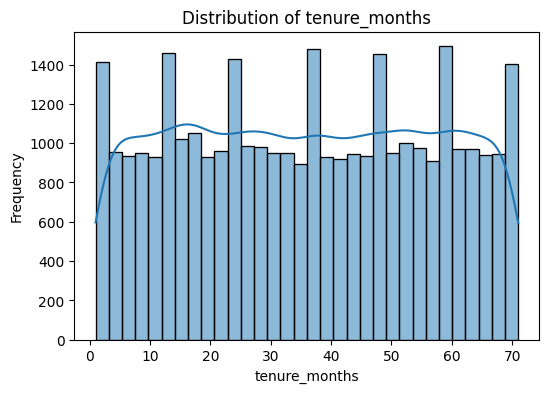

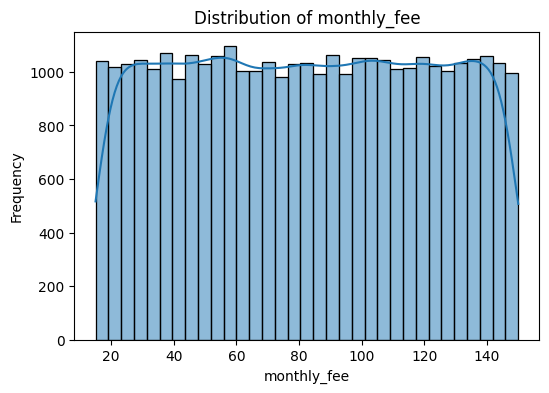

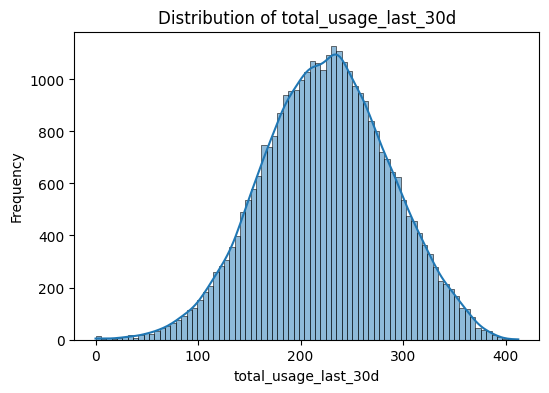

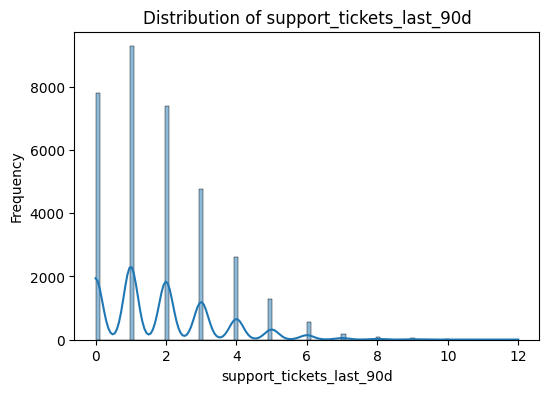

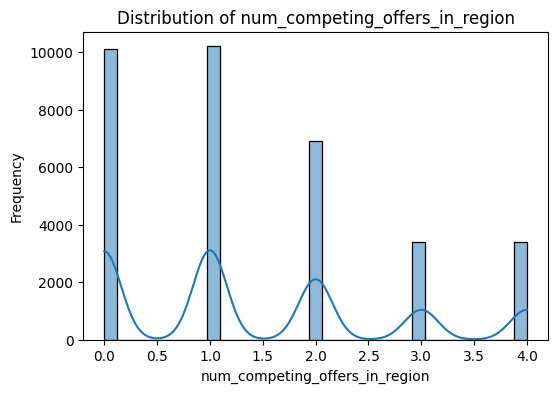

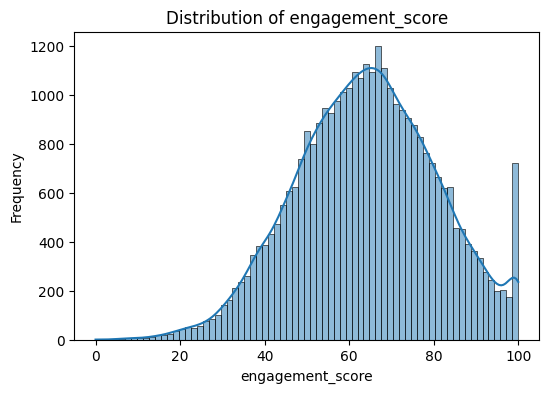

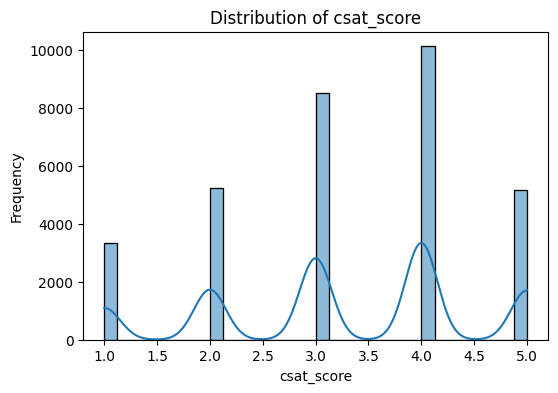

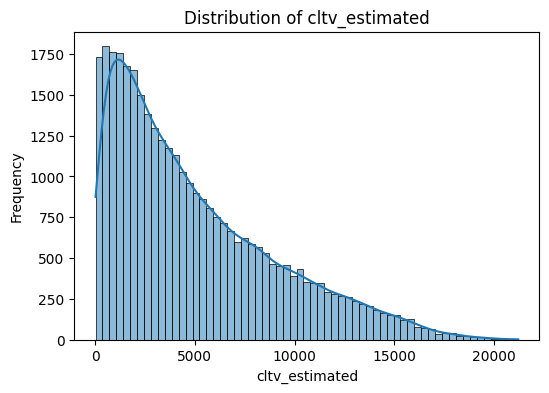

In [108]:
numeric_cols=[
    "tenure_months",
    "monthly_fee",
    "total_usage_last_30d",
    "support_tickets_last_90d",
    "num_competing_offers_in_region",
    "engagement_score",
    "csat_score",
    "cltv_estimated"
]
for col in numeric_cols:
    plt.figure(figsize=(6,4))

    sns.histplot(data=plot_df,x=col,kde=True)

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    
    plt.show()

*   For Monthly Distribution we can see there are higher yearly tenures such as 12,24,36 Years.
*   The total_usage_last_30d is normally distributed.
*   We can see the customer lifetime value is right skewed means more people are less valuble and very less people have very high value. 

Churn Rate V/S Numerical Features

In [109]:
# Churn rate vs tenure
# Churn rate vs monthly fee
# Churn rate vs engagement score
# Churn rate vs CSAT

Churn Rate by Tenure Group:
 tenure_group
0-6      21.901408
7-12     20.787513
13-24    16.587356
25-36    11.590909
37+       6.381072
Name: churn_next_30d, dtype: float64


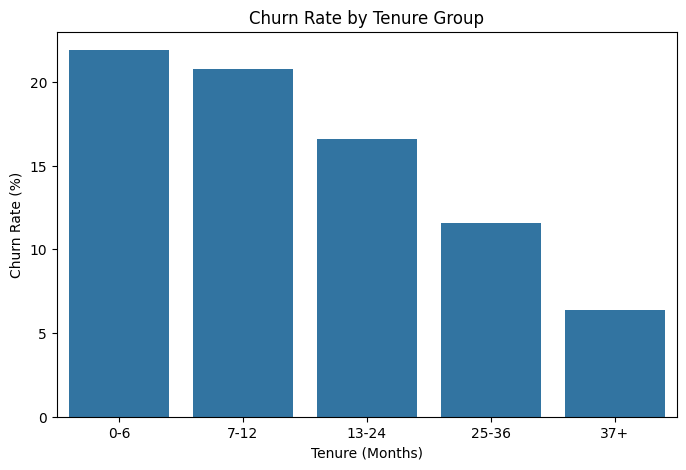

In [110]:
# Churn rate vs tenure
plot_df["tenure_group"]= pd.cut(
    plot_df["tenure_months"],
    bins=[0,6,12,24,36,float('inf')],
     labels=["0-6", "7-12", "13-24", "25-36", "37+"]
)
tenure_churn_rate=(
    plot_df.groupby("tenure_group",observed=True)["churn_next_30d"]
    .mean().mul(100)
)
print("Churn Rate by Tenure Group:\n",tenure_churn_rate)
plt.figure(figsize=(8, 5))

sns.barplot(
    x=tenure_churn_rate.index,
    y=tenure_churn_rate.values
)

plt.title("Churn Rate by Tenure Group")
plt.xlabel("Tenure (Months)")
plt.ylabel("Churn Rate (%)")

plt.show()

* People who have longer tenure are less likely to churn in next 30 days.

Churn Rate by Monthly Fee Group:
 monthly_fee_group
(14.865, 42.0]    10.956292
(42.0, 69.0]      11.676691
(69.0, 96.0]      11.236288
(96.0, 123.0]     11.722523
(123.0, 150.0]    11.980548
Name: churn_next_30d, dtype: float64


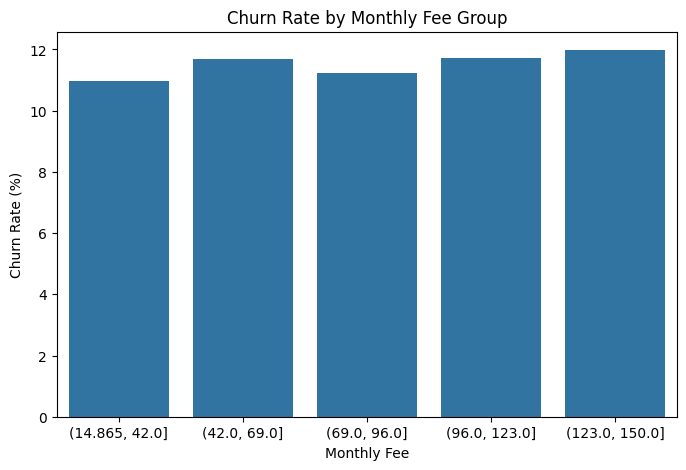

In [111]:
#churn rate vs monthly fee
plot_df["monthly_fee_group"]= pd.cut(
    plot_df["monthly_fee"],
    bins=5)
monthly_fee_churn_rate=(
    plot_df.groupby("monthly_fee_group",observed=True)["churn_next_30d"]
    .mean().mul(100)
)
print("Churn Rate by Monthly Fee Group:\n",monthly_fee_churn_rate)
plt.figure(figsize=(8, 5))

sns.barplot(
    x=monthly_fee_churn_rate.index,
    y=monthly_fee_churn_rate.values
)

plt.title("Churn Rate by Monthly Fee Group")
plt.xlabel("Monthly Fee")
plt.ylabel("Churn Rate (%)")

plt.show()

Churn Rate by Engagement Group:
 engagement_group
(-0.001, 20.0]    56.050955
(20.0, 40.0]      38.634436
(40.0, 60.0]      17.312734
(60.0, 80.0]       6.080791
(80.0, 100.0]      1.906234
Name: churn_next_30d, dtype: float64


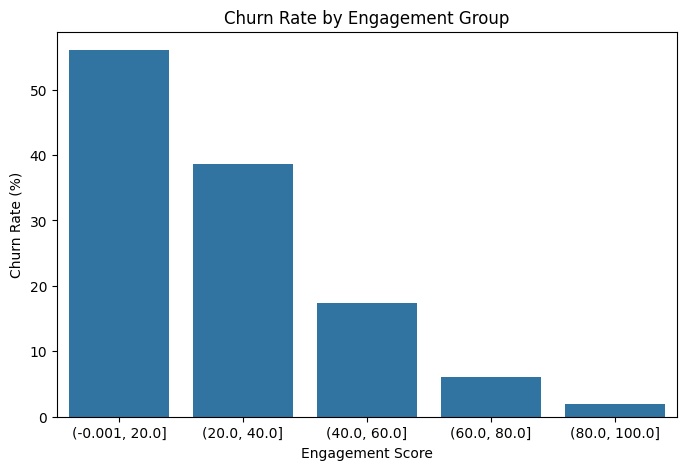

In [112]:
#churn rate vs engagement score
df_clean["engagement_group"] = pd.cut(
    df_clean["engagement_score"],
    bins=[0, 20, 40, 60, 80, 100],
    include_lowest=True
)
engagement_churn_rate=(
    df_clean.groupby("engagement_group",observed=True)["churn_next_30d"]
    .mean().mul(100)
)
print("Churn Rate by Engagement Group:\n",engagement_churn_rate)
plt.figure(figsize=(8, 5))

sns.barplot(
    x=engagement_churn_rate.index,
    y=engagement_churn_rate.values
)

plt.title("Churn Rate by Engagement Group")
plt.xlabel("Engagement Score")
plt.ylabel("Churn Rate (%)")

plt.show()

* People who have higher engagement score are very less likely to churn.

support_tickets_last_90d
0      2.898551
1      5.958410
2     10.463540
3     17.546064
4     24.741082
5     33.411397
6     43.727599
7     57.591623
8     71.084337
9     92.105263
10    50.000000
12    50.000000
Name: churn_next_30d, dtype: float64


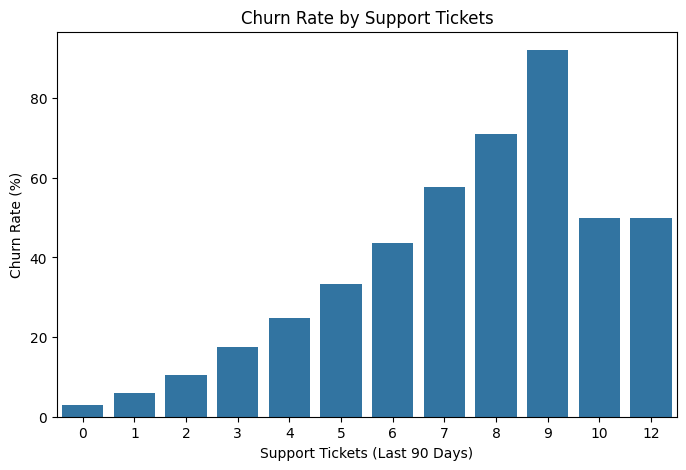

In [113]:
#churn rate vs support tickets last 90 days
support_churn = (
    df_clean.groupby("support_tickets_last_90d")["churn_next_30d"]
    .mean()
    .mul(100)
)

print(support_churn)
plt.figure(figsize=(8, 5))

sns.barplot(
    x=support_churn.index,
    y=support_churn.values
)

plt.title("Churn Rate by Support Tickets")
plt.xlabel("Support Tickets (Last 90 Days)")
plt.ylabel("Churn Rate (%)")

plt.show()

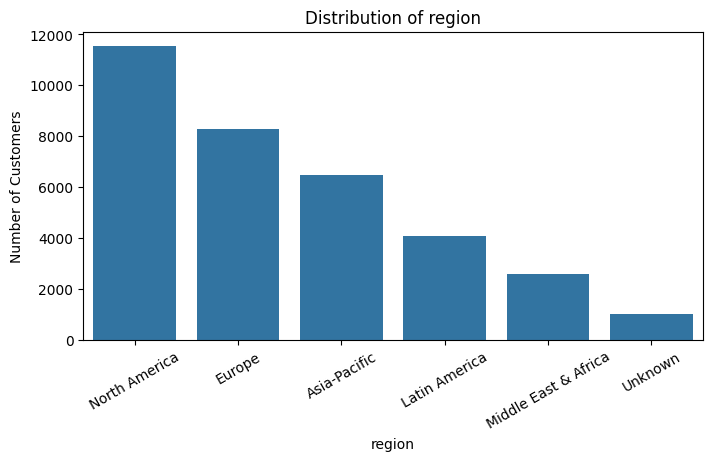

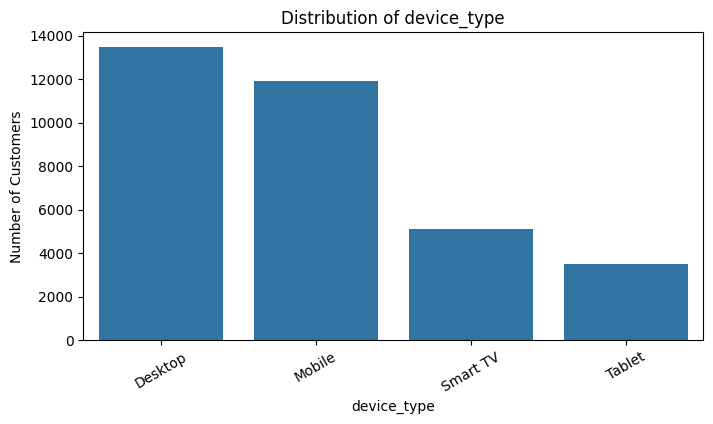

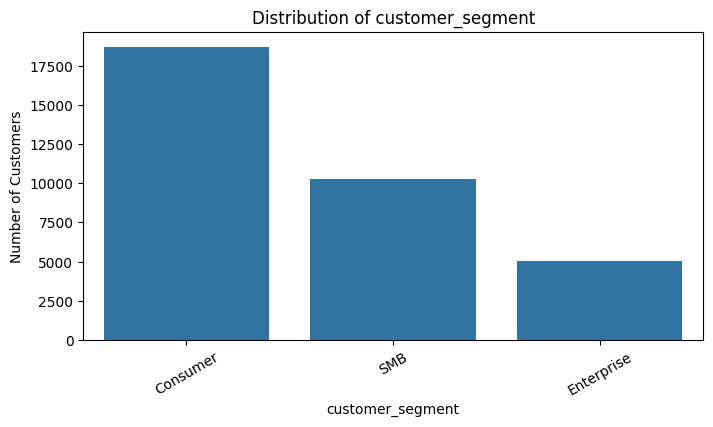

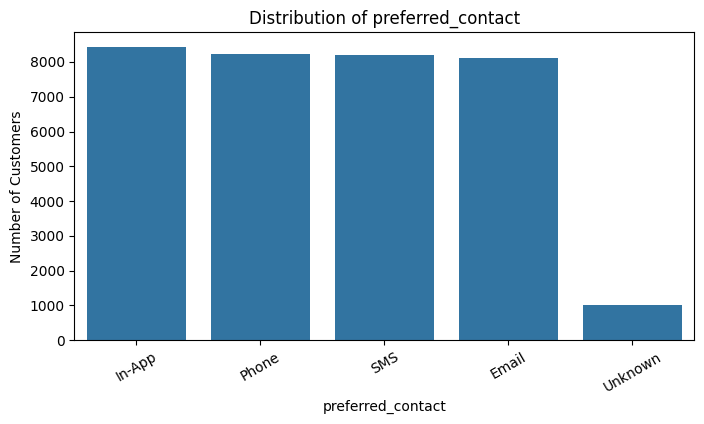

C:\Users\Admin\AppData\Local\Temp\ipykernel_7668\3719336635.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  plot_df[col] = plot_df[col].astype("object").fillna("Unknown")


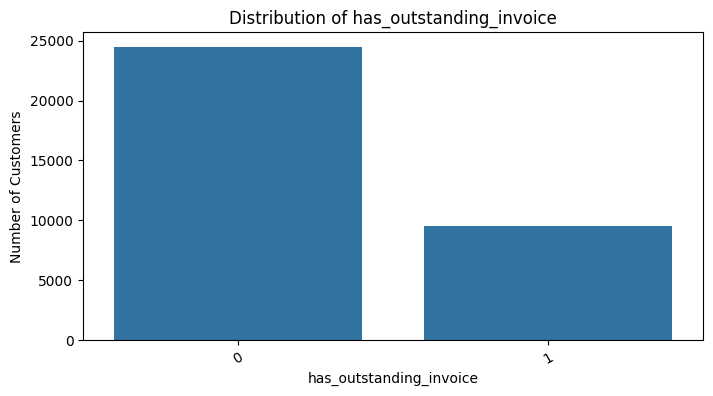

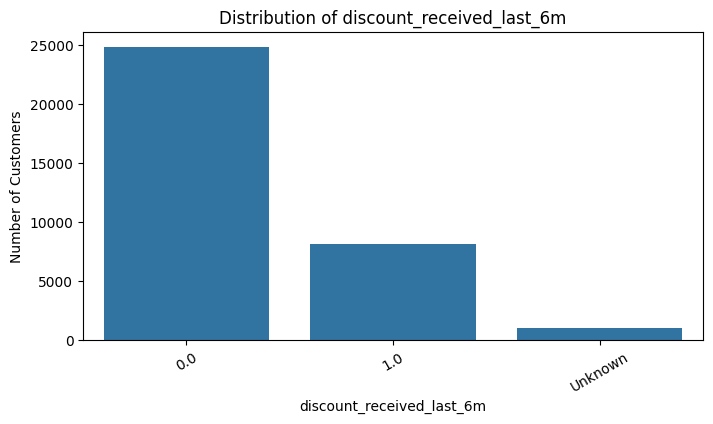

C:\Users\Admin\AppData\Local\Temp\ipykernel_7668\3719336635.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  plot_df[col] = plot_df[col].astype("object").fillna("Unknown")


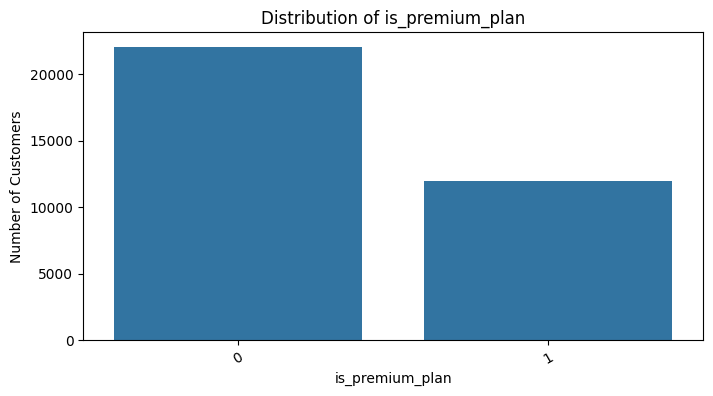

In [114]:
categorical_features = [
    "region",
    "device_type",
    "customer_segment",
    "preferred_contact",
    "has_outstanding_invoice",
    "discount_received_last_6m",
    "is_premium_plan"
]
for col in categorical_features:
    plt.figure(figsize=(8, 4))
    plot_df[col] = plot_df[col].astype("object").fillna("Unknown")
    sns.countplot(
        data=plot_df,
        x=col,
        order=plot_df[col].value_counts(dropna=False).index
    )
    
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Number of Customers")
    plt.xticks(rotation=30)
    
    plt.show()

In [115]:
for col in categorical_features:

    churn_rate=(
        plot_df.groupby(col)['churn_next_30d'].mean().sort_values(ascending=False)*100
    )
    print(f"Churn Rate by {col}:\n{churn_rate}\n")

Churn Rate by region:
region
Europe                  12.387035
Asia-Pacific            11.307965
Middle East & Africa    11.300310
North America           11.238293
Unknown                 11.176471
Latin America           11.070201
Name: churn_next_30d, dtype: float64

Churn Rate by device_type:
device_type
Tablet      12.135089
Mobile      11.634163
Desktop     11.378134
Smart TV    11.173947
Name: churn_next_30d, dtype: float64

Churn Rate by customer_segment:
customer_segment
SMB           11.793372
Enterprise    11.467890
Consumer      11.374559
Name: churn_next_30d, dtype: float64

Churn Rate by preferred_contact:
preferred_contact
Unknown    12.254902
Email      11.719808
In-App     11.694935
Phone      11.485582
SMS        11.063726
Name: churn_next_30d, dtype: float64

Churn Rate by has_outstanding_invoice:
has_outstanding_invoice
1    19.86532
0     8.27482
Name: churn_next_30d, dtype: float64

Churn Rate by discount_received_last_6m:
discount_received_last_6m
0.0        12.3

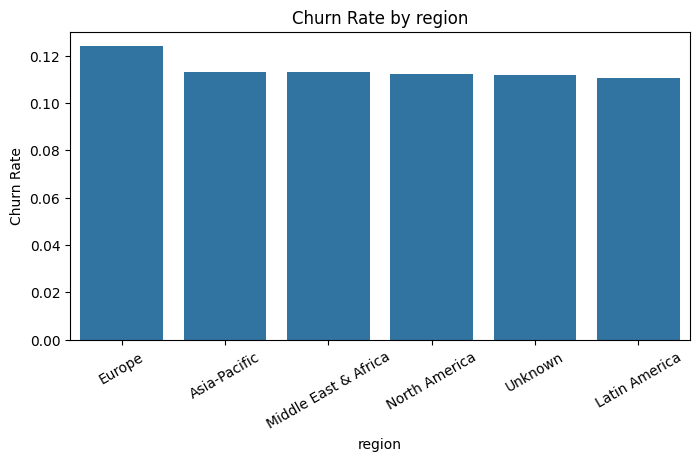

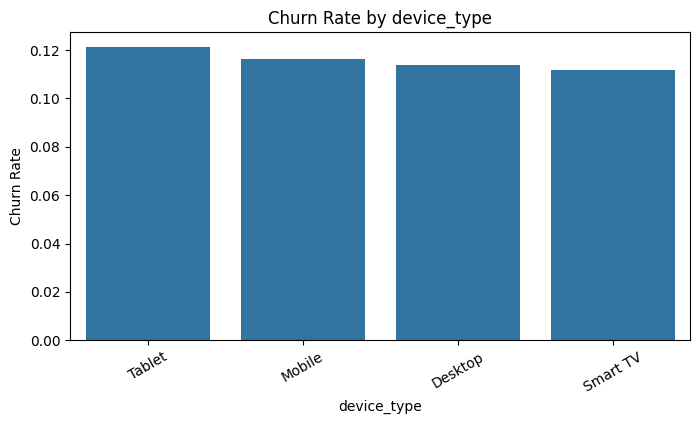

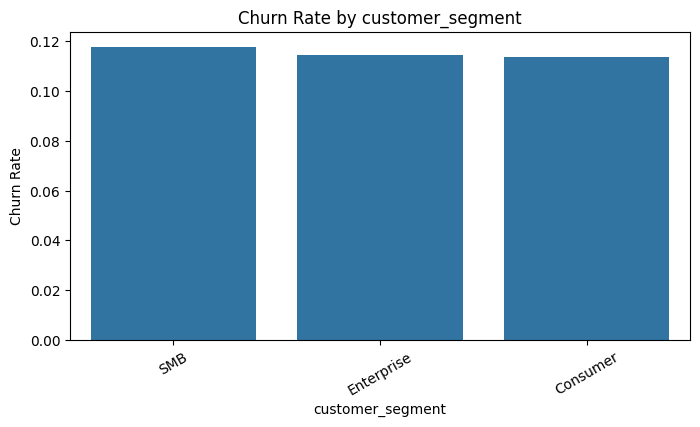

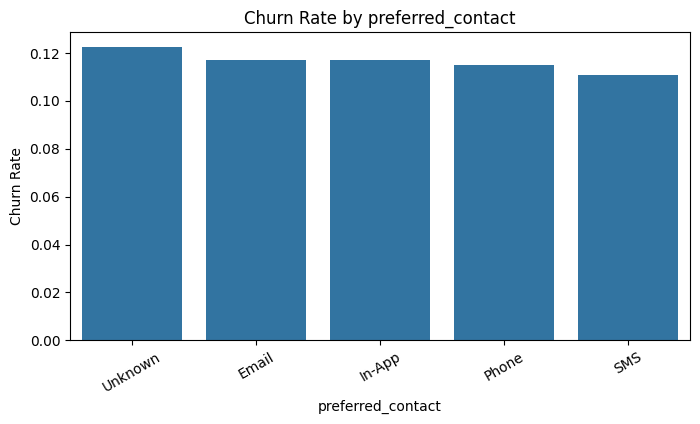

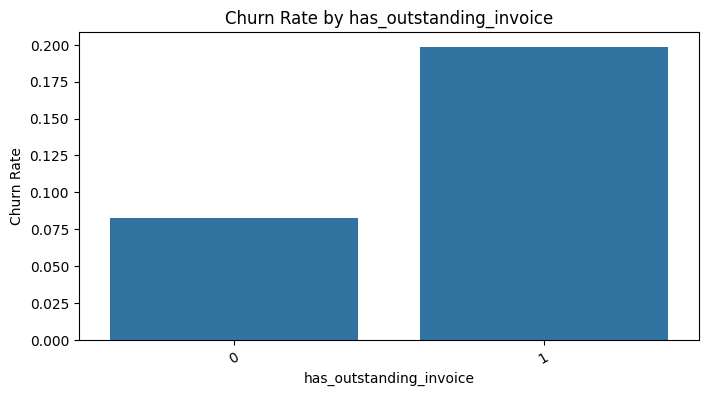

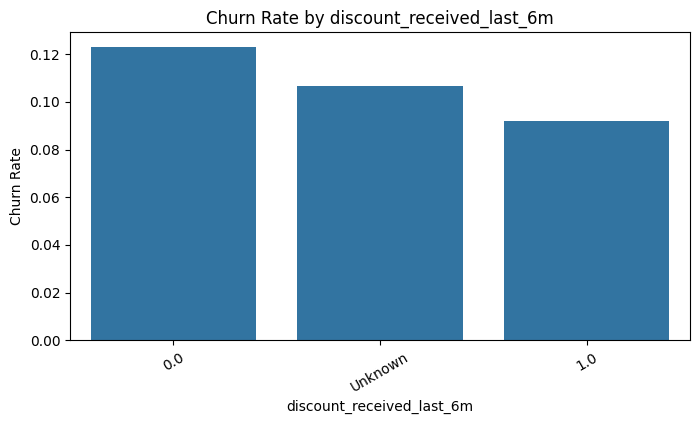

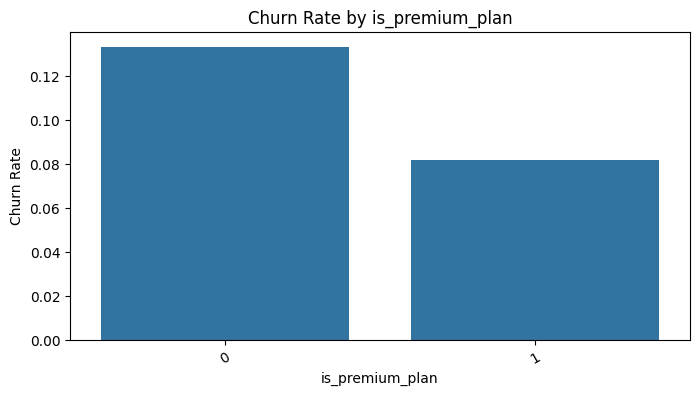

In [116]:
for col in categorical_features:

    churn_rate=(
        plot_df.groupby(col)['churn_next_30d'].mean().sort_values(ascending=False)
    )
    plt.figure(figsize=(8, 4))

    sns.barplot(
        x=churn_rate.index,
        y=churn_rate.values
    )
    plt.title(f"Churn Rate by {col}")
    plt.xlabel(col)
    plt.ylabel("Churn Rate")
    
    plt.xticks(rotation=30)
    plt.show()

* People who have out standing invoice have higher chance of churning in next 1 month.
* Also, People who have premium plan are very less likely to churn than people who don't have premiu plan.